In [4]:
!pip install kagglehub

In [39]:
import sys
print(sys.executable)
print(sys.version)

C:\Users\kecyb\AppData\Local\Programs\Python\Python314\python.exe
3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]


In [40]:
import sys
!{sys.executable} -m pip install kagglehub

In [41]:
import kagglehub
 
print("KaggleHub imported successfully!")

KaggleHub imported successfully!


In [42]:
path = kagglehub.dataset_download("yeanzc/telco-customer-churn-ibm-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\kecyb\.cache\kagglehub\datasets\yeanzc\telco-customer-churn-ibm-dataset\versions\1


In [43]:
import kagglehub
import pandas as pd
import os
 
path = kagglehub.dataset_download("yeanzc/telco-customer-churn-ibm-dataset")
 
print("Path:", path)
 
print(os.listdir(path))
file_path = os.path.join(path, "Telco_customer_churn.csv")
#with open(file_path, 'r',encoding='utf-8-sig') as f:
    #for i in range(10):
        #print(repr(f.readline()))
df =pd.read_csv(file_path,encoding='utf-8-sig',engine='python')
df.info()


Path: C:\Users\kecyb\.cache\kagglehub\datasets\yeanzc\telco-customer-churn-ibm-dataset\versions\1
['Telco_customer_churn.csv', 'Telco_customer_churn.xlsx']
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043

In [44]:
df.shape

(7043, 33)

In [45]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [46]:
#find missing value
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [47]:
#seems like all other have no missing value except the churn reason column so we need to find out the lebel of this 
df["Churn Label"].value_counts()

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [48]:
df[['Churn Label', 'Churn Reason']].head(20)   #trying to figure out the reason

,Churn Label,Churn Reason
0,Yes,Competitor made better offer
1,Yes,Moved
2,Yes,Moved
3,Yes,Moved
4,Yes,Competitor had better devices
5,Yes,Competitor offered higher download speeds
6,Yes,Competitor offered more data
7,Yes,Competitor made better offer
8,Yes,Competitor had better devices
9,Yes,Competitor had better devices


In [49]:
#dropping identifier not needed
X = df.drop([
'CustomerID',
'Churn Label',
'Churn Score',
'Churn Reason',
'Lat Long'
], axis=1)
 
y = df['Churn Value']

In [50]:
df = df[
[
'Contract',
'Tenure Months',
'Monthly Charges',
'Total Charges',
'Tech Support',
'Online Security',
'Internet Service',
'Payment Method',
'Churn Value'
]
]
df.head()

,Contract,Tenure Months,Monthly Charges,Total Charges,Tech Support,Online Security,Internet Service,Payment Method,Churn Value
0,Month-to-month,2,53.85,108.15,No,Yes,DSL,Mailed check,1
1,Month-to-month,2,70.70,151.65,No,No,Fiber optic,Electronic check,1
2,Month-to-month,8,99.65,820.5,No,No,Fiber optic,Electronic check,1
3,Month-to-month,28,104.80,3046.05,Yes,No,Fiber optic,Electronic check,1
4,Month-to-month,49,103.70,5036.3,No,No,Fiber optic,Bank transfer (automatic),1


In [51]:
df.dtypes

Contract                str
Tenure Months         int64
Monthly Charges     float64
Total Charges           str
Tech Support            str
Online Security         str
Internet Service        str
Payment Method          str
Churn Value           int64
dtype: object

In [52]:
df['Total Charges'] = pd.to_numeric( #preprocessing
df['Total Charges'],
errors='coerce'
)

In [53]:
df.isnull().sum()    #trying again to check missing value

Contract             0
Tenure Months        0
Monthly Charges      0
Total Charges       11
Tech Support         0
Online Security      0
Internet Service     0
Payment Method       0
Churn Value          0
dtype: int64

In [54]:
#No one has missing value except total charges so filling with median here
df['Total Charges'] = df['Total Charges'].fillna(
df['Total Charges'].median()
)
df.isnull().sum()    #rechecking missing value

Contract            0
Tenure Months       0
Monthly Charges     0
Total Charges       0
Tech Support        0
Online Security     0
Internet Service    0
Payment Method      0
Churn Value         0
dtype: int64

In [55]:
#doing encoding to convert all columns text into numbers
df_encoded = pd.get_dummies(
df,
drop_first=True
)
df_encoded.head()


,Tenure Months,Monthly Charges,Total Charges,Churn Value,Contract_One year,Contract_Two year,Tech Support_No internet service,Tech Support_Yes,Online Security_No internet service,Online Security_Yes,Internet Service_Fiber optic,Internet Service_No,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,2,53.85,108.15,1,False,False,False,False,False,True,False,False,False,False,True
1,2,70.70,151.65,1,False,False,False,False,False,False,True,False,False,True,False
2,8,99.65,820.50,1,False,False,False,False,False,False,True,False,False,True,False
3,28,104.80,3046.05,1,False,False,False,True,False,False,True,False,False,True,False
4,49,103.70,5036.30,1,False,False,False,False,False,False,True,False,False,False,False


In [56]:
df_encoded.shape

(7043, 15)

In [57]:
df_encoded.columns

Index(['Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Value',
       'Contract_One year', 'Contract_Two year',
       'Tech Support_No internet service', 'Tech Support_Yes',
       'Online Security_No internet service', 'Online Security_Yes',
       'Internet Service_Fiber optic', 'Internet Service_No',
       'Payment Method_Credit card (automatic)',
       'Payment Method_Electronic check', 'Payment Method_Mailed check'],
      dtype='str')

In [58]:
X = df_encoded.drop('Churn Value', axis=1)   #input variable feature are not given to model
 
y = df_encoded['Churn Value']          #churn output variable for prediction

In [59]:
#80/20 split
from sklearn.model_selection import train_test_split
 
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.2,
stratify=y,
random_state=42
)

In [60]:
#logistic regression(baseline)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
lr = LogisticRegression(max_iter=1000)
 
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
print(classification_report(y_test, y_pred))    # precision ,recall,f1 score


              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.63      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409



In [61]:
from sklearn.metrics import roc_auc_score
#finding how good if model can detect churn and non churn
y_prob = lr.predict_proba(X_test)[:,1]
 
auc = roc_auc_score(y_test, y_prob)
 
print("ROC-AUC:", auc)

ROC-AUC: 0.8386783435376786


In [62]:
import pandas as pd
 
coef_df = pd.DataFrame({
'Feature': X.columns,
'Coefficient': lr.coef_[0]
})
 
coef_df.sort_values(
by='Coefficient',
ascending=False
)

,Feature,Coefficient
9,Internet Service_Fiber optic,0.605396
12,Payment Method_Electronic check,0.452036
1,Monthly Charges,0.005691
13,Payment Method_Mailed check,0.003472
2,Total Charges,0.000275
11,Payment Method_Credit card (automatic),-0.041247
0,Tenure Months,-0.051423
7,Online Security_No internet service,-0.330645
5,Tech Support_No internet service,-0.330645
10,Internet Service_No,-0.330645


In [63]:
from sklearn.tree import DecisionTreeClassifier
 
dt = DecisionTreeClassifier(
max_depth=4,
random_state=42
)
 
dt.fit(X_train, y_train)
 
y_pred_tree = dt.predict(X_test)
 
print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.64      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [64]:
from sklearn.metrics import roc_auc_score   #for decision tree
 
y_prob_tree = dt.predict_proba(X_test)[:,1]
 
auc_tree = roc_auc_score(y_test, y_prob_tree)
 
print("Decision Tree ROC-AUC:", auc_tree)

Decision Tree ROC-AUC: 0.8317975147898422


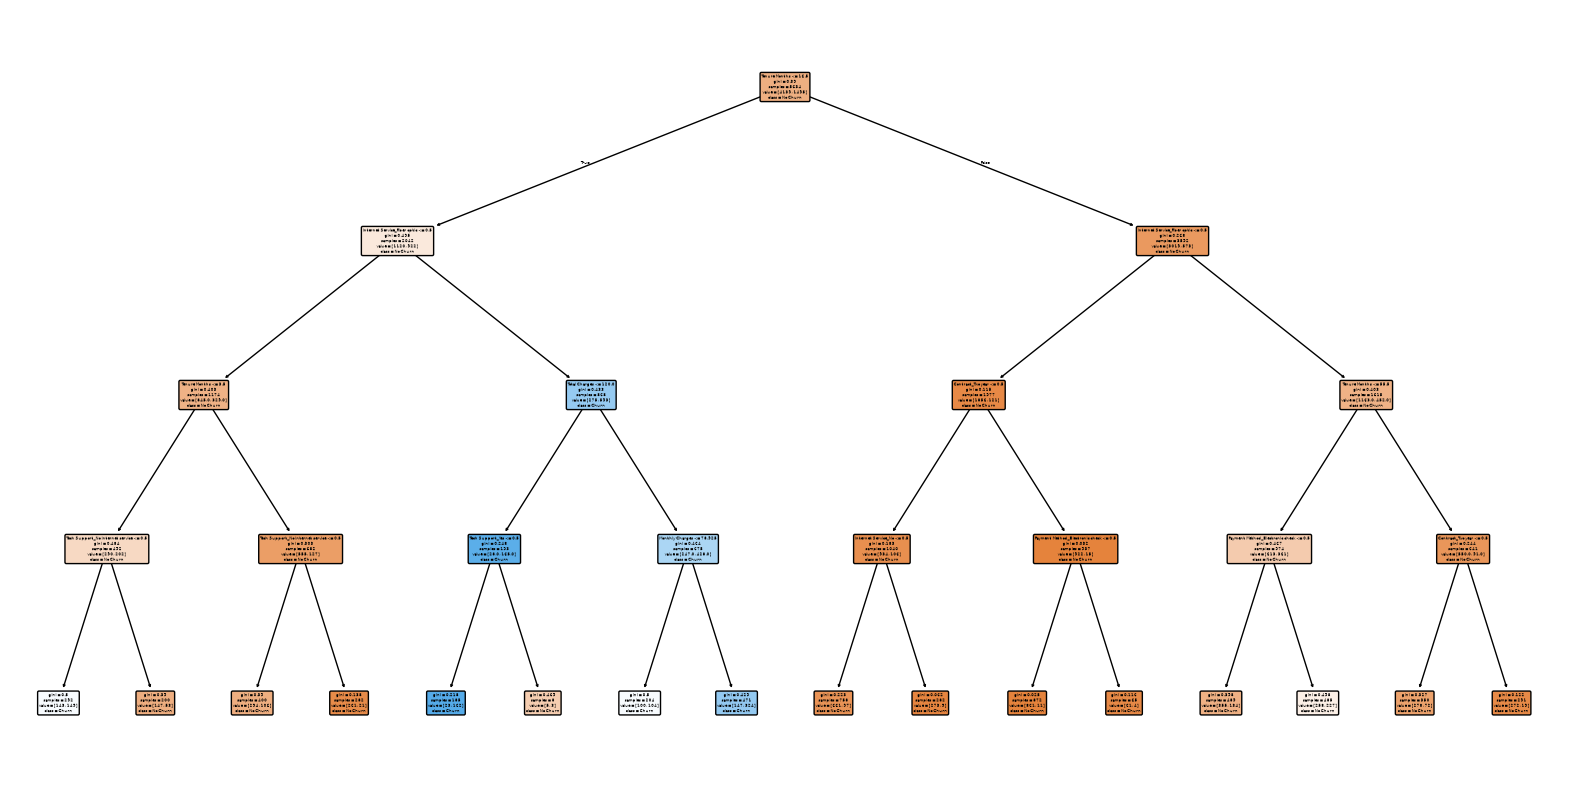

In [65]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
 
plt.figure(figsize=(20,10))
 
plot_tree(
dt,
feature_names=X.columns,
class_names=["No Churn", "Churn"],
filled=True,
rounded=True
)
 
plt.show()

In [66]:
from sklearn.tree import export_text
 
rules = export_text(
dt,
feature_names=list(X.columns)
)
 
print(rules)

|--- Tenure Months <= 16.50
|   |--- Internet Service_Fiber optic <= 0.50
|   |   |--- Tenure Months <= 3.50
|   |   |   |--- Tech Support_No internet service <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Tech Support_No internet service >  0.50
|   |   |   |   |--- class: 0
|   |   |--- Tenure Months >  3.50
|   |   |   |--- Tech Support_No internet service <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Tech Support_No internet service >  0.50
|   |   |   |   |--- class: 0
|   |--- Internet Service_Fiber optic >  0.50
|   |   |--- Total Charges <= 120.00
|   |   |   |--- Tech Support_Yes <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Tech Support_Yes >  0.50
|   |   |   |   |--- class: 0
|   |   |--- Total Charges >  120.00
|   |   |   |--- Monthly Charges <= 78.92
|   |   |   |   |--- class: 1
|   |   |   |--- Monthly Charges >  78.92
|   |   |   |   |--- class: 1
|--- Tenure Months >  16.50
|   |--- Internet Service_Fiber optic <= 0.50
|   |   |--- Contract_

In [67]:
print(export_text(dt, feature_names=list(X.columns)))

|--- Tenure Months <= 16.50
|   |--- Internet Service_Fiber optic <= 0.50
|   |   |--- Tenure Months <= 3.50
|   |   |   |--- Tech Support_No internet service <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Tech Support_No internet service >  0.50
|   |   |   |   |--- class: 0
|   |   |--- Tenure Months >  3.50
|   |   |   |--- Tech Support_No internet service <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Tech Support_No internet service >  0.50
|   |   |   |   |--- class: 0
|   |--- Internet Service_Fiber optic >  0.50
|   |   |--- Total Charges <= 120.00
|   |   |   |--- Tech Support_Yes <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Tech Support_Yes >  0.50
|   |   |   |   |--- class: 0
|   |   |--- Total Charges >  120.00
|   |   |   |--- Monthly Charges <= 78.92
|   |   |   |   |--- class: 1
|   |   |   |--- Monthly Charges >  78.92
|   |   |   |   |--- class: 1
|--- Tenure Months >  16.50
|   |--- Internet Service_Fiber optic <= 0.50
|   |   |--- Contract_

In [72]:
# Extract feature names after One-Hot Encoding
encoded_cat_cols = (
    log_reg_pipeline.named_steps['prep']
    .named_transformers_['cat']
    .get_feature_names_out(cat_cols)
)
all_feature_names = num_cols + list(encoded_cat_cols)
# 1. Logistic Regression Coefficients (Beta Weights & Odds Ratios)
lr_model = log_reg_pipeline.named_steps['model']
lr_importance = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient (Beta)': lr_model.coef_[0],
    'Odds Ratio (exp(Beta))': np.exp(lr_model.coef_[0])
}).sort_values(by='Coefficient (Beta)', ascending=False)

print("--- TOP CHURN DRIVERS (LOGISTIC REGRESSION) ---")
print(lr_importance.head(10).to_string(index=False))

print("\n--- TOP RETENTION DRIVERS (LOGISTIC REGRESSION) ---")
print(lr_importance.tail(10).to_string(index=False))

# 2. Decision Tree Feature Importance
dt_model = dt_pipeline.named_steps['model']
dt_importance = pd.DataFrame({
    'Feature': all_feature_names,
    'Gini Importance': dt_model.feature_importances_
}).sort_values(by='Gini Importance', ascending=False)

print("\n--- TOP 10 FEATURES IN DECISION TREE ---")
print(dt_importance.head(10).to_string(index=False))

--- TOP CHURN DRIVERS (LOGISTIC REGRESSION) ---
                       Feature  Coefficient (Beta)  Odds Ratio (exp(Beta))
   InternetService_Fiber optic            1.121685                3.070024
                  TotalCharges            0.641811                1.899918
PaymentMethod_Electronic check            0.386286                1.471506
               StreamingTV_Yes            0.374880                1.454818
             MultipleLines_Yes            0.362680                1.437175
           StreamingMovies_Yes            0.347601                1.415667
          PaperlessBilling_Yes            0.290723                1.337394
               SeniorCitizen_1            0.195363                1.215752
    PaymentMethod_Mailed check            0.076969                1.080009
          DeviceProtection_Yes            0.073764                1.076553

--- TOP RETENTION DRIVERS (LOGISTIC REGRESSION) ---
                           Feature  Coefficient (Beta)  Odds Ratio (exp(Be

In [73]:
#trainvstestcomparison(check for outfitting)
def check_generalization(name, pipeline, X_tr, y_tr, X_te, y_te):
    train_acc = pipeline.score(X_tr, y_tr)
    test_acc = pipeline.score(X_te, y_te)
    train_auc = roc_auc_score(y_tr, pipeline.predict_proba(X_tr)[:, 1])
    test_auc = roc_auc_score(y_te, pipeline.predict_proba(X_te)[:, 1])
    return {
        'Model': name,
        'Train Acc': round(train_acc, 4),
        'Test Acc': round(test_acc, 4),
        'Train AUC': round(train_auc, 4),
        'Test AUC': round(test_auc, 4),
        'Generalization Gap (AUC)': round(train_auc - test_auc, 4)
    }

gen_df = pd.DataFrame([
    check_generalization("Logistic Regression", log_reg_pipeline, X_train, y_train, X_test, y_test),
    check_generalization("Decision Tree (Depth=5)", dt_pipeline, X_train, y_train, X_test, y_test)
])

print("--- OVERFITTING / GENERALIZATION CHECK ---")
print(gen_df.to_string(index=False))


--- OVERFITTING / GENERALIZATION CHECK ---
                  Model  Train Acc  Test Acc  Train AUC  Test AUC  Generalization Gap (AUC)
    Logistic Regression     0.8048    0.8045     0.8506    0.8361                    0.0145
Decision Tree (Depth=5)     0.8011    0.7783     0.8471    0.8195                    0.0275


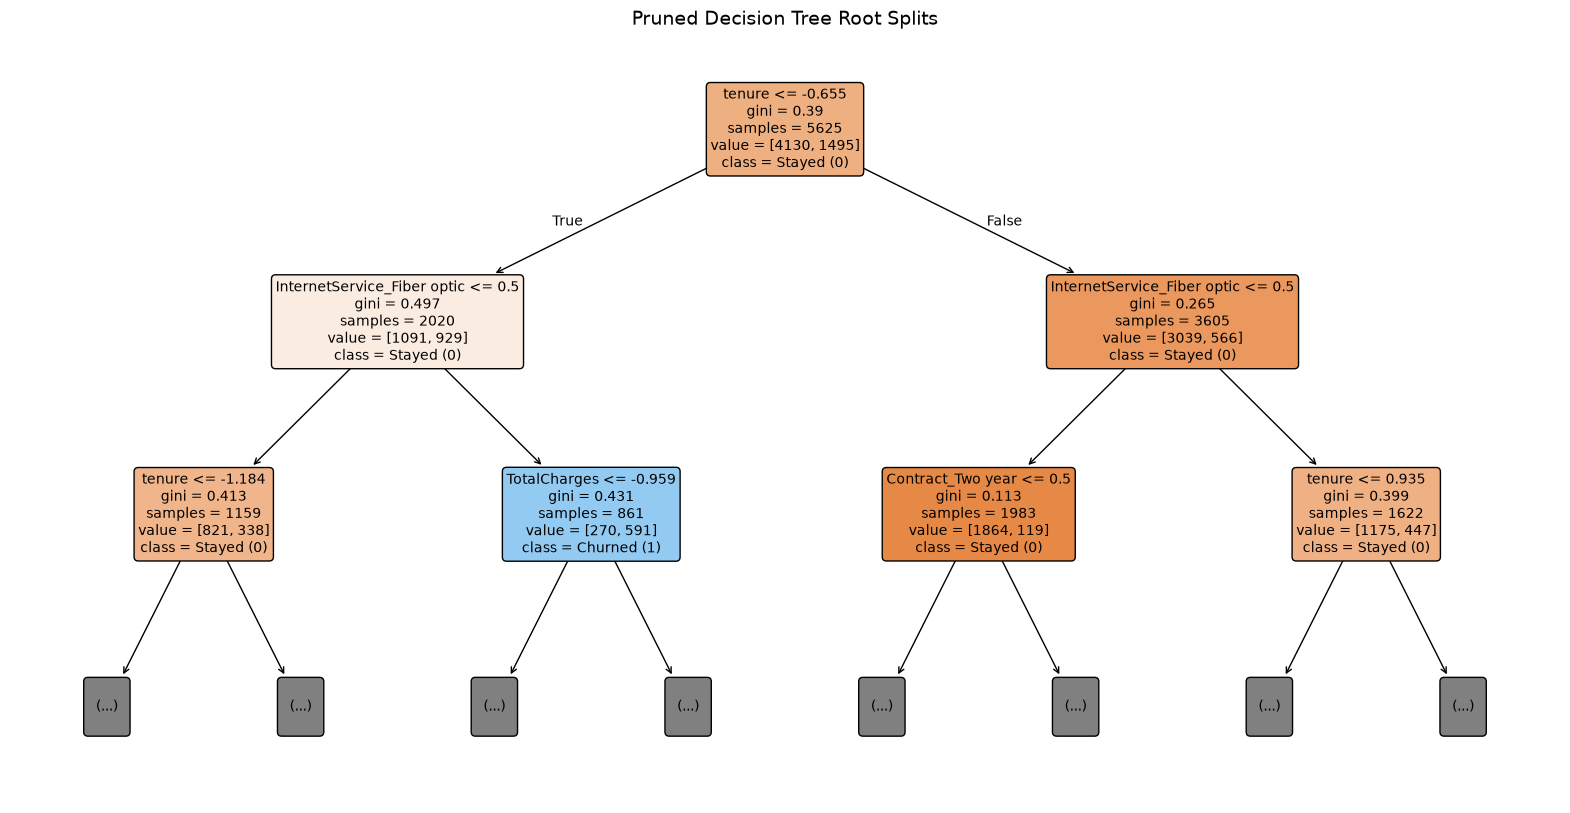

In [74]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=all_feature_names,
    class_names=['Stayed (0)', 'Churned (1)'],
    filled=True,
    rounded=True,
    max_depth=2,  # Show top 2 levels for readability
    fontsize=10
)
plt.title("Pruned Decision Tree Root Splits", fontsize=14)
plt.show()

In [75]:
# Compute metrics function
def get_metrics(model_name, split, y_true, y_pred, y_prob):
    return {
        'Model': model_name,
        'Dataset': split,
        'Accuracy': round(accuracy_score(y_true, y_pred), 4),
        'Precision (Churn)': round(precision_score(y_true, y_pred), 4),
        'Recall (Churn)': round(recall_score(y_true, y_pred), 4),
        'F1-Score': round(f1_score(y_true, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_true, y_prob), 4)
    }

# Predictions for train set
y_train_pred_lr = log_reg_pipeline.predict(X_train)
y_train_prob_lr = log_reg_pipeline.predict_proba(X_train)[:, 1]

y_train_pred_dt = dt_pipeline.predict(X_train)
y_train_prob_dt = dt_pipeline.predict_proba(X_train)[:, 1]

# Build table
summary_data = [
    get_metrics("Logistic Regression", "Train", y_train, y_train_pred_lr, y_train_prob_lr),
    get_metrics("Logistic Regression", "Test", y_test, y_pred_lr, y_prob_lr),
    get_metrics("Decision Tree (Depth=5)", "Train", y_train, y_train_pred_dt, y_train_prob_dt),
    get_metrics("Decision Tree (Depth=5)", "Test", y_test, y_pred_dt, y_prob_dt),
]

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

                  Model Dataset  Accuracy  Precision (Churn)  Recall (Churn)  F1-Score  ROC-AUC
    Logistic Regression   Train    0.8048             0.6592          0.5498    0.5996   0.8506
    Logistic Regression    Test    0.8045             0.6505          0.5722    0.6088   0.8361
Decision Tree (Depth=5)   Train    0.8011             0.6295          0.6114    0.6203   0.8471
Decision Tree (Depth=5)    Test    0.7783             0.5807          0.5963    0.5884   0.8195


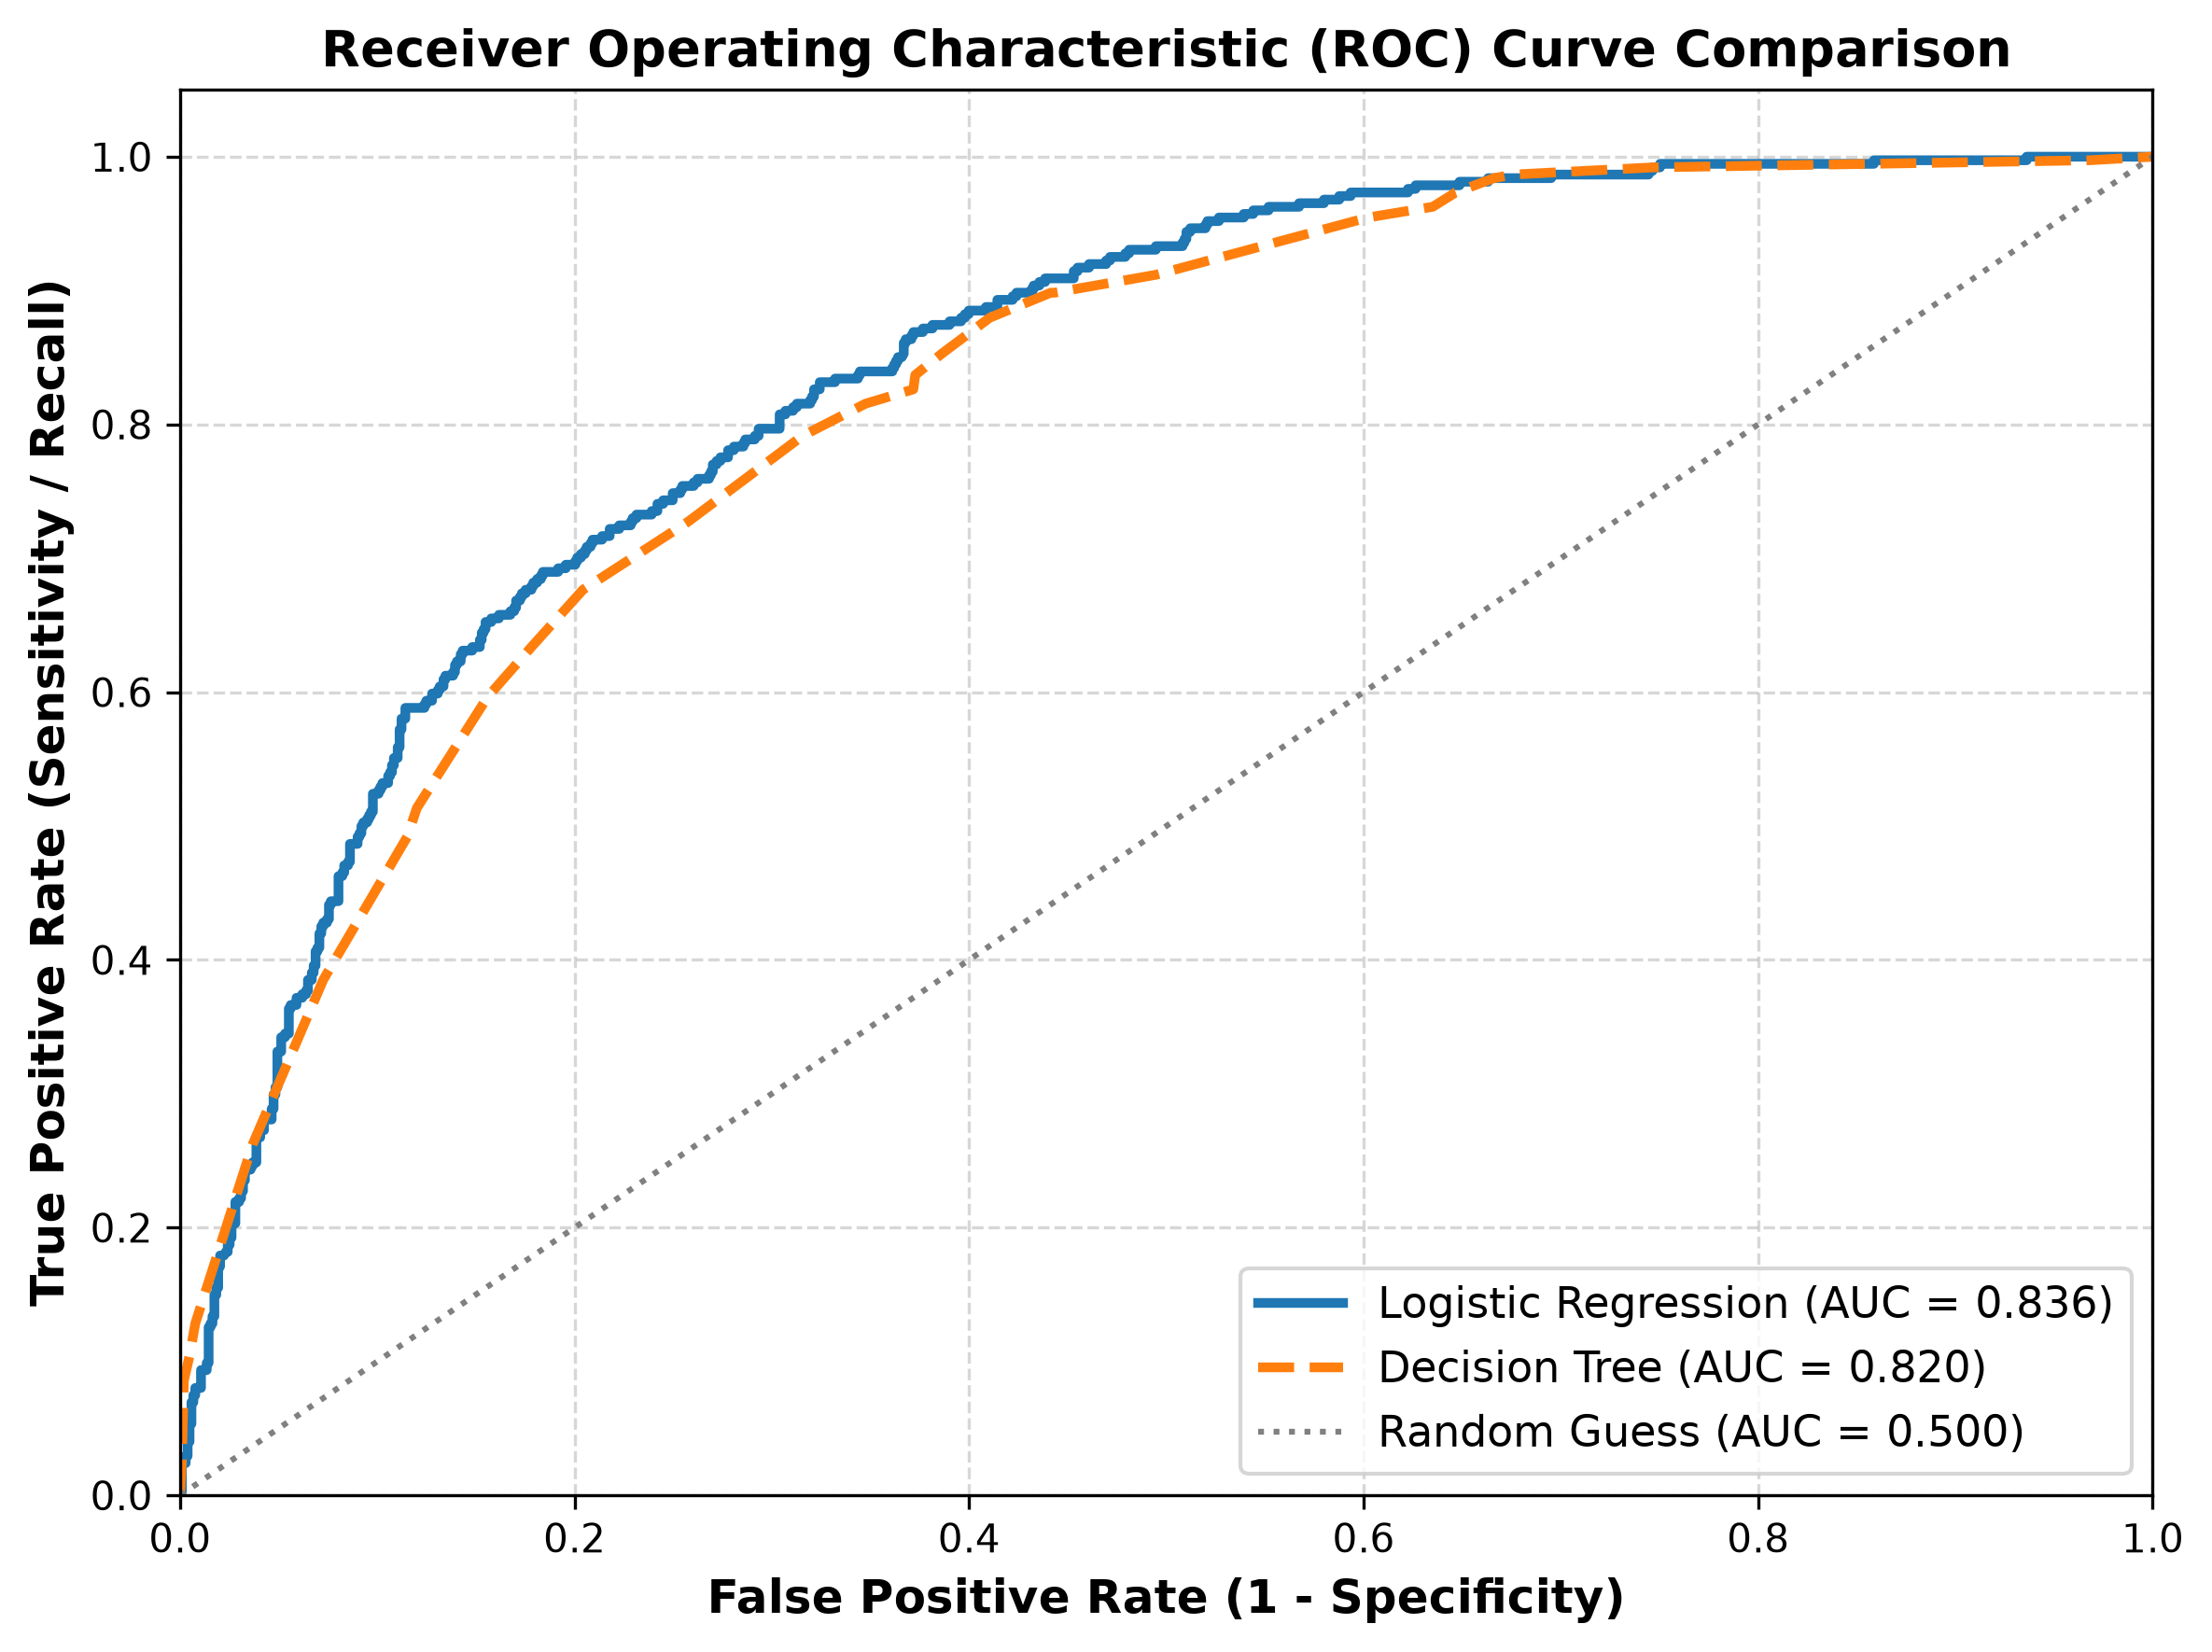

In [76]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Calculate False Positive Rate (FPR), True Positive Rate (TPR), and AUC
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)

# 2. Configure the Plot
plt.figure(figsize=(8, 6), dpi=300)

# Logistic Regression Curve (Smooth, parametric)
plt.plot(
    fpr_lr, tpr_lr,
    color='#1f77b4', lw=2.5,
    label=f'Logistic Regression (AUC = {auc_lr:.3f})'
)

# Decision Tree Curve (Stepped splits)
plt.plot(
    fpr_dt, tpr_dt,
    color='#ff7f0e', lw=2.5, linestyle='--',
    label=f'Decision Tree (AUC = {auc_dt:.3f})'
)

# Baseline: Random Chance (Diagonal 45-degree line)
plt.plot(
    [0, 1], [0, 1],
    color='gray', linestyle=':', lw=1.5,
    label='Random Guess (AUC = 0.500)'
)

# 3. Graph Styling & Annotations
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12, fontweight='bold')
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11, frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)

# 4. Save and Show
plt.tight_layout()
plt.savefig('roc_curve_comparison.png', dpi=300, bbox_inches='tight')
plt.show()